## Test training


In [1]:
%load_ext autoreload
%autoreload 1

%aimport quantdata
%aimport quantdata.biz_calendar
%aimport quantdata.widb
%aimport quantdata.widb.client
%aimport quantdata.widb.day
%aimport quantdata.widb.timeseries
%aimport quantdata.dysanos
%aimport quantdata.utils.backbone
%aimport quantdata.torch
%aimport quantdata.torch.bbtorch
%aimport quantdata.torch.ffw
%aimport quantdata.dysanos.simple
%aimport quantdata.dysanos.simple.sampler
%aimport quantdata.dysanos.simple.model
%aimport quantdata.dysanos.simple.trainer
%aimport quantdata.dysanos.simple.aec

from quantdata.dysanos.simple.aec import load_data
sampler = load_data(["SPX"])
print("/done")

00: Importing torch...done; this took 0.00381ms.
00: Generating samples for 1 tickers SPX with from 2015-01-01 to 2025-07-01... done; this took 0.26s.
00: Found the following number of samples per ticker: SPX: 2617.
00: Found date range 2015-01-02 to 2025-07-01 with 2617 total dates. First validation date for 25 steps per sample is 2023-05-01.
00: Using up to 1000 options per date.
01:   Ticker SPX: using 411 training samples (accross 2079 training dates), and 103 validation samples (accross 538 validation dates).
00: Created 411 training samples and 103 validation samples based on the date split at 2023-05-01. That implies 20% of all samples are validation samples.
00: Total time taken: 0.3s.
/done


## AEC

Cleaning up memory... done.
Model AEC train_vol_vol_linattn 1.2 [756ad94a|fa6007dd3ce42e6d] created.
00: Trainer for 'AEC train_vol_vol_linattn 1.2 [756ad94a|fa6007dd3ce42e6d]'
00: =======================================================================
01:   Model is ready. Current epoch to train is 0.
01:   Experiment path is /media/storage/quantdata/experiments/dysanos/simple/fa6007dd3ce42e6d/v1/train_vol_vol_linattn bf61ca31/.
00: Launching 'AEC train_vol_vol_linattn 1.2 [756ad94a|fa6007dd3ce42e6d]' training for 1000 epochs over 411 training and 103 validation samples, using a mini bastch size of 128 for 100 batches per epoch, and a batch size of 64 for valuation.
01:   This model has 30353 parameters.
01:   Starting afresh.
00: Training 'train_vol_vol_linattn' epoch 1/1000 error avg trn 272.7; val 58.07/70.56 [38s 0.58s 0.17s]. LR: 1.00e-03, GN 2.8, excess_weighted: 0.004279/0.003413, excess_weighted_avg: 0.004981/0.003294, excess_spread: 63.28/71.18, excess_spread_avg: 58.51/71.18

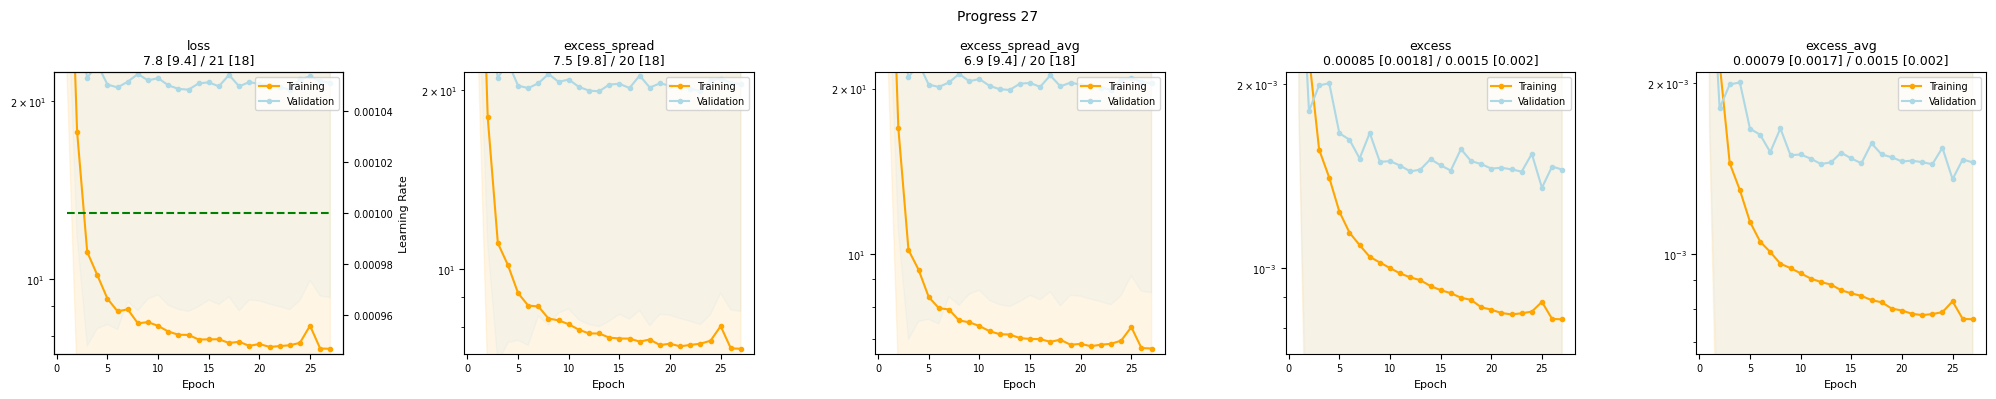

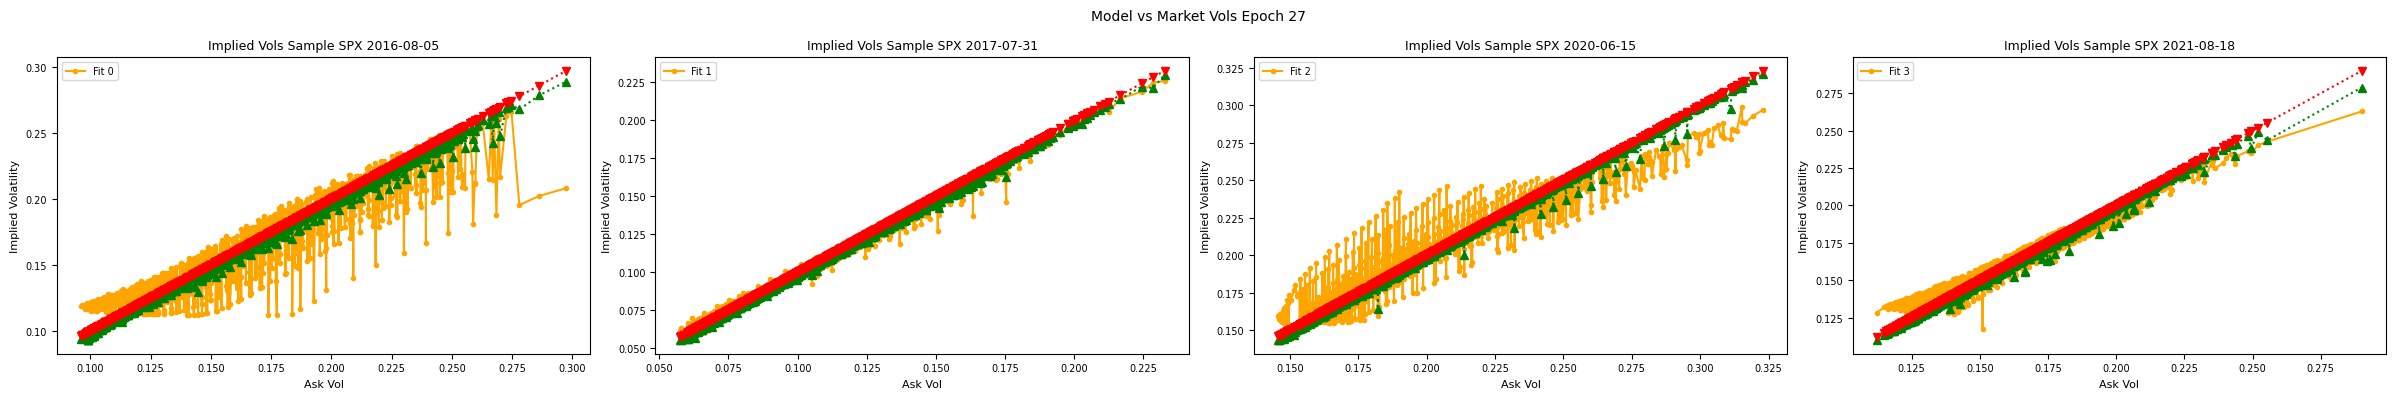

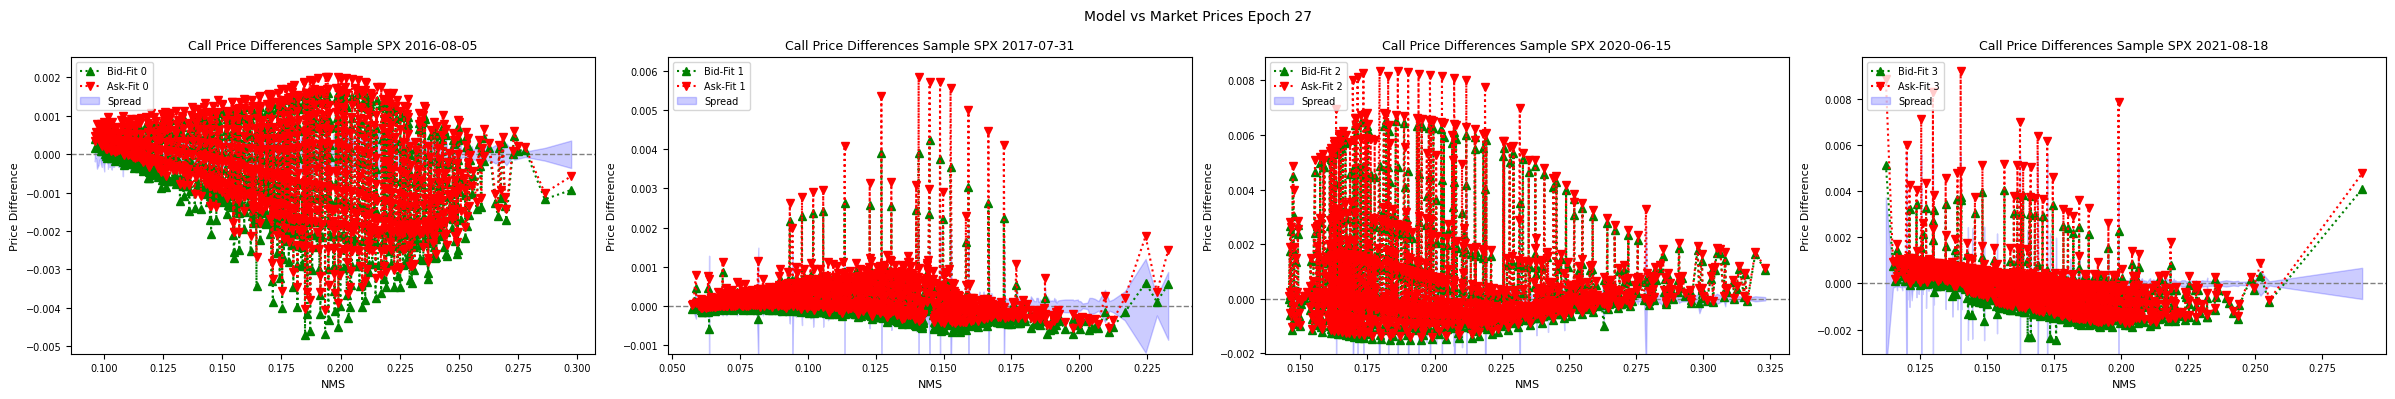

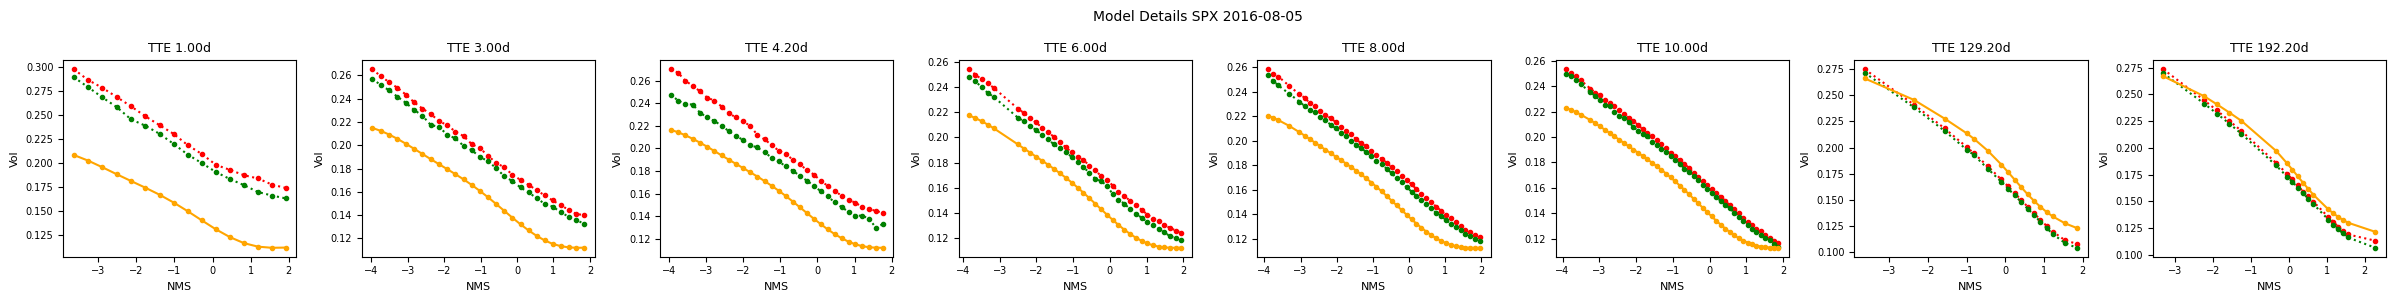

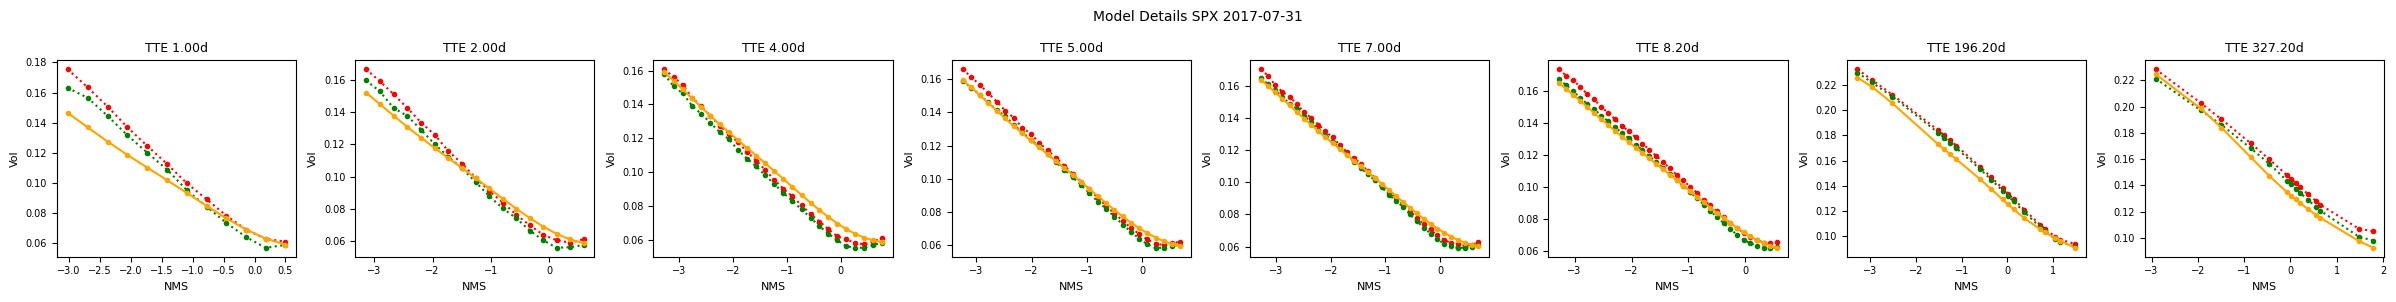

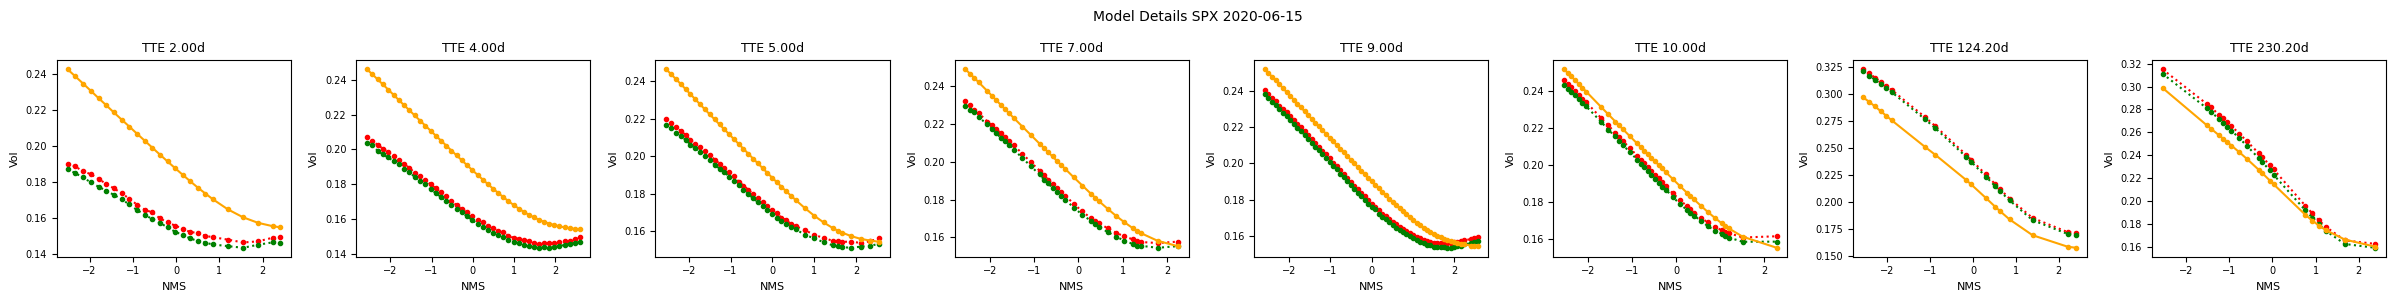

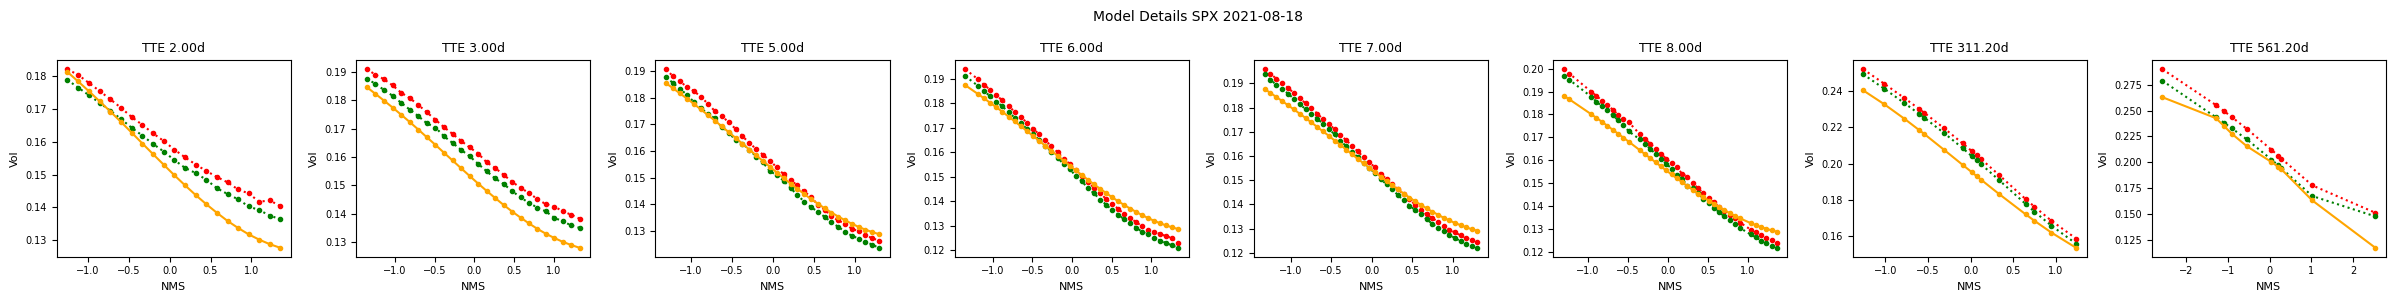

00: Training 'train_vol_vol_linattn' epoch 2/1000 error avg trn 53; val 17.76/27.15 [1:16 0.58s 0.17s]. LR: 1.00e-03, GN 23.94, excess_weighted: 0.001216/0.001267, excess_weighted_avg: 0.001694/0.001269, excess_spread: 17.98/26.42, excess_spread_avg: 16.94/26.42, excess: 0.002218/0.001804, excess_avg: 0.002167/0.001804. ETA: 22:16:13.
00: Training 'train_vol_vol_linattn' epoch 3/1000 error avg trn 18.46; val 11.1/21.91 [1:54 0.58s 0.17s]. LR: 1.00e-03, GN 83.39, excess_weighted: 0.0007484/0.001006, excess_weighted_avg: 0.001063/0.001084, excess_spread: 11.07/20.97, excess_spread_avg: 10.17/20.97, excess: 0.001562/0.001986, excess_avg: 0.001443/0.001986. ETA: 33:31:45.
01:   Epoch 3: Saving new best validation loss 21.91 vs. 70.56 at epoch 1 to '/media/storage/quantdata/experiments/dysanos/simple/fa6007dd3ce42e6d/v1/train_vol_vol_linattn bf61ca31/best.pt'... done; this took 0.026s.
01:   Saving checkpoint to /media/storage/quantdata/experiments/dysanos/simple/fa6007dd3ce42e6d/v1/train_v

In [ ]:
from quantdata.dysanos.simple.model import *
from quantdata.dysanos.simple.aec import *

aec_config = AEC.Config(
    # core pararmeters
    encode_what = "vol",
    fit_what    = "vol",
    num_state   = 64,
    fit_average = True,

    encoder = AttentionPoolingEncoderFactory(
        num_head = 64,
        num_QK = 8,
        V_config = FeedForward.Config(
            num_depth = 0, # linear
            num_width = 64, # head
            activation = 'Softplus',
        ),
        QK_config = FeedForward.Config(
            num_depth = 0,  # linear
            num_width = 16, # twice num_QK
            activation = 'ReLU', # idea is to be sparse...?
        ),
        head_config = FeedForward.Config(
            num_depth = 2,
            num_width = 64, # head
            activation = 'ReLU', # idea is to be sparse...?
        )
    ),
    decoder = GatingDecoderFactory(
        num_head = 16,
        num_QK = 4,        
        V_config = FeedForward.Config(
            num_depth = 2,
            num_width = 32, # twice head
            activation = 'Softplus',    
        ),
        QK_config = FeedForward.Config(
            num_depth = 0, # linear
            num_width = 4, # equal QK
            activation = 'ReLU', # idea is to be sparse...?
        ),
        head_config = FeedForward.Config(
            num_depth = 2,
            num_width = 32, # twice head
            activation = 'Softplus',
        )
    ),
)

with torch.compiler.set_stance("force_eager"):
    run( ipynbname.name(), version="1.2", aec_config=aec_config, sampler=sampler, epochs = 1000, batch_per_epoch = 100, debug=False, val_batch_size=64 )
